In [1]:
import numpy as np 
import pandas as pd 
import matplotlib.pyplot as plt 
import seaborn as sns 
from sklearn.preprocessing import LabelEncoder,StandardScaler,PowerTransformer
from sklearn.model_selection import train_test_split,cross_val_score,KFold,cross_validate,StratifiedKFold
from sklearn.compose import ColumnTransformer
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import make_pipeline,Pipeline
from sklearn.metrics import roc_curve, auc,classification_report,roc_auc_score


## Table of contents 

**1. Checking the missing values and the unique values** <br />
**2. Doing the EDA part**  <br />
**3. Checking the skewness and the outliers**  <br />
**4. Applying Transformations and scaling**   <br />
**5. Model building with cross-validation** <br />
**6. Getting the evaluation metrics, depending on the regression and the classification, different metrics**

In [227]:
data =  pd.read_csv("./data/Student_Depression_Dataset.csv")
data.head()

,Gender,Age,Family_background,Relationship_status,Marital_status,Living_style,Current_semester,CGPA,friend_circle,Health_condition,Cost_without_study,Home_division,Depression
0,Female,22,Middle class,Single,Unmarried,Bachelor,8,3.43,Yes,Critical,10113,Chittagong,Yes
1,Male,19,Middle class,Single,Unmarried,Bachelor,2,3.70,Yes,Abnormal,13815,Chittagong,Yes
2,Male,23,Middle class,Single,Unmarried,Family,8,3.28,No,Abnormal,15450,Dhaka,Yes
3,Male,20,Middle class,Complicated,Unmarried,Family,2,3.77,No,Good,17413,Dhaka,No
4,Female,21,Middle class,Single,Unmarried,Family,1,4.00,No,Abnormal,16693,Dhaka,Yes


### 1) Getting the Missing & unique values

In [228]:
print("Missing values : \n",data.isnull().mean() * 100)
print("....")

df =  data.copy()
encoders = {}
for x in data.columns:
    
    le =  LabelEncoder()
    if data[x].dtype == "O":
        print(f"{x} : {data[x].unique()}")
        df[x] =  le.fit_transform(data[x])
        encoders[x] =  le 
        

data.head(3)

Missing values : 
 Gender                 0.0
Age                    0.0
Family_background      0.0
Relationship_status    0.0
Marital_status         0.0
Living_style           0.0
Current_semester       0.0
CGPA                   0.0
friend_circle          0.0
Health_condition       0.0
Cost_without_study     0.0
Home_division          0.0
Depression             0.0
dtype: float64
....
Gender : ['Female' 'Male']
Family_background : ['Middle class' 'Lower Middle class' 'Rich class']
Relationship_status : ['Single' 'Complicated' 'In a Relationship']
Marital_status : ['Unmarried' 'Married' 'Separated']
Living_style : ['Bachelor' 'Family']
friend_circle : ['Yes' 'No']
Health_condition : ['Critical' 'Abnormal' 'Good' 'Normal']
Home_division : ['Chittagong' 'Dhaka' 'Rajshahi' 'Mymensingh' 'Barisal' 'Rangpur' 'Khulna'
 'Sylhet']
Depression : ['Yes' 'No']


,Gender,Age,Family_background,Relationship_status,Marital_status,Living_style,Current_semester,CGPA,friend_circle,Health_condition,Cost_without_study,Home_division,Depression
0,Female,22,Middle class,Single,Unmarried,Bachelor,8,3.43,Yes,Critical,10113,Chittagong,Yes
1,Male,19,Middle class,Single,Unmarried,Bachelor,2,3.70,Yes,Abnormal,13815,Chittagong,Yes
2,Male,23,Middle class,Single,Unmarried,Family,8,3.28,No,Abnormal,15450,Dhaka,Yes


In [229]:
df.head(3)

,Gender,Age,Family_background,Relationship_status,Marital_status,Living_style,Current_semester,CGPA,friend_circle,Health_condition,Cost_without_study,Home_division,Depression
0,0,22,1,2,2,0,8,3.43,1,1,10113,1,1
1,1,19,1,2,2,0,2,3.70,1,0,13815,1,1
2,1,23,1,2,2,1,8,3.28,0,0,15450,2,1


### 2) EDA 
**NOTE : we will use `data` for EDA but use `df` for model building** 

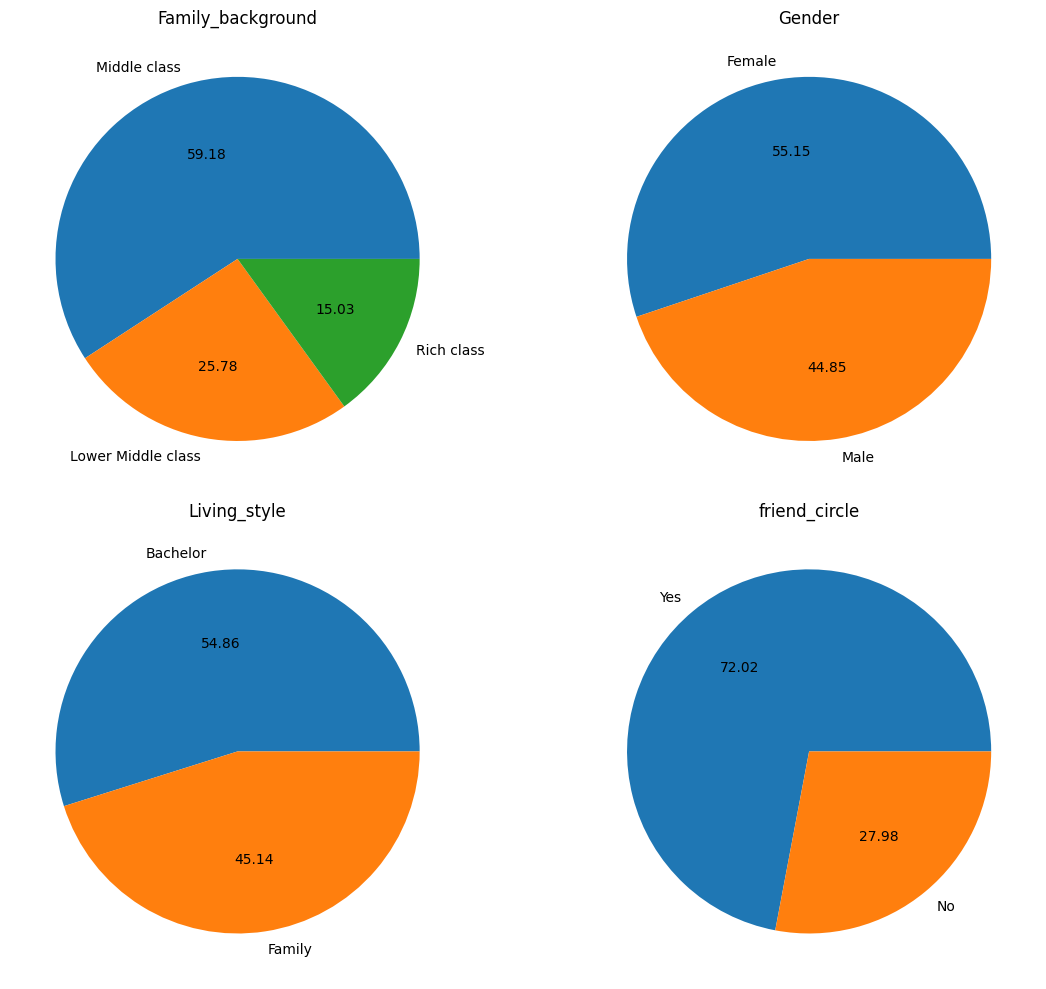

In [230]:
import matplotlib.pyplot as plt

cols = ["Family_background", "Gender", "Living_style", "friend_circle"]   # put your 4 column names here

fig, axes = plt.subplots(2, 2, figsize=(12, 10))

for ax, col in zip(axes.flatten(), cols):
    data[col].value_counts().plot(kind="pie", autopct="%.2f", ax=ax)
    ax.set_title(col)
    ax.set_ylabel("")        # removes the column name pandas puts on the side

plt.tight_layout()
plt.show()

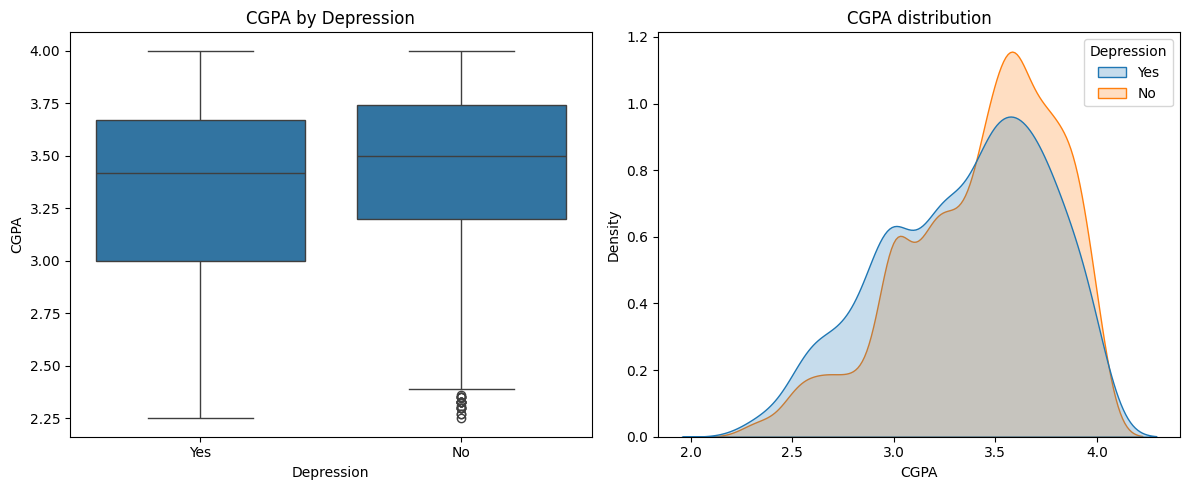

In [231]:
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

sns.boxplot(data=data, x="Depression", y="CGPA", ax=axes[0])
axes[0].set_title("CGPA by Depression")

sns.kdeplot(data=data, x="CGPA", hue="Depression", fill=True, common_norm=False, ax=axes[1])
axes[1].set_title("CGPA distribution")

plt.tight_layout()
plt.show()

<Axes: xlabel='friend_circle', ylabel='count'>

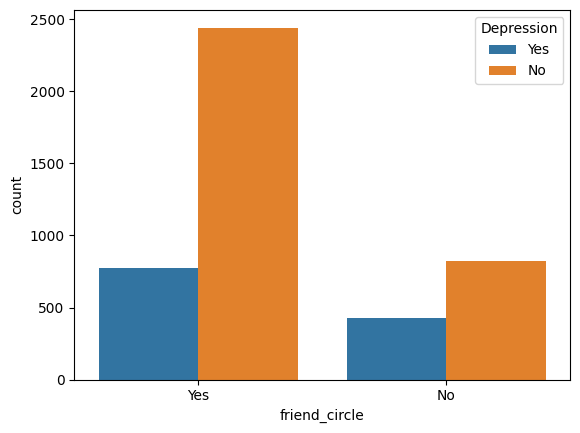

In [232]:
sns.countplot(data=data, x="friend_circle", hue="Depression")

<Axes: xlabel='Family_background', ylabel='count'>

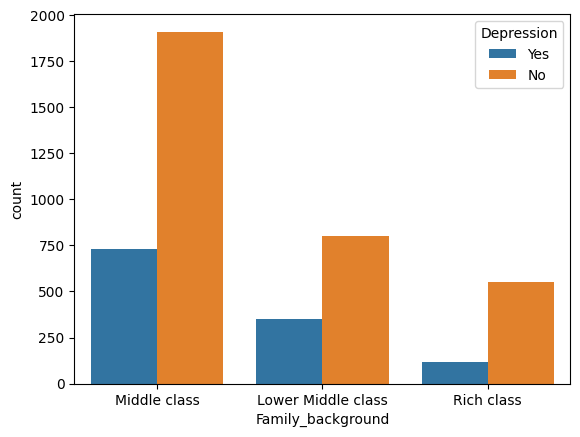

In [233]:
sns.countplot(data=data, x="Family_background", hue="Depression")

<b> We came to the conclusion that:
1. A middle-class family person is more depressed than any other class.
2. Females are more depressed.
3. Lower CGPA leads to more depression.
4. Not having a friend circle leads to more depression </b>

### 3)  Checking the Skewness 

In [234]:
x =  df.drop(columns=["Depression"])
y =  df["Depression"]
x_train,x_test,y_train,y_test =  train_test_split(x,y,test_size=0.2,stratify=y)

In [235]:
for x in x_train.columns:
    if str(x_train[x].dtype) in ["int32","int64","float64"]:
        print(f"{x} : ",x_train[x].skew())

Gender :  0.19762317247617261
Age :  0.14346360708802508
Family_background :  0.09267834912563529
Relationship_status :  -1.0046053467038756
Marital_status :  -1.6609507172178226
Living_style :  0.21356087996596815
Current_semester :  0.3237913807967265
CGPA :  -0.6078019005363942
friend_circle :  -0.9879384435365638
Health_condition :  -0.5090682839605988
Cost_without_study :  0.8325331670561139
Home_division :  0.4610876573373559


### Thought Process After Checking Skewness

1. **Is it numeric?** Ignore skew on categorical/encoded columns because it only shows class imbalance.
2. **Does my model care?** Tree models don't, so skip the fix. Linear, SVM, KNN and neural networks do.
3. **How strong is it?**
   - |skew| < 0.5 → leave it
   - 0.5 to 1 → optional
   - &gt; 1 → fix it
4. **Why is it skewed?** Use a box plot to check for data errors and outliers, and clean those first.
5. **Which direction?**
   - Right skew → `log1p` or `sqrt`
   - Left skew → square it, or reflect it and then log
   - Unsure/both → `PowerTransformer`
6. **Scale after the transform.** `PowerTransformer` already scales, but `log` needs `StandardScaler` after it.
7. **Fit on train only**, then use `transform` on the test set.
8. **Check the result.** Calculate skew again, and keep the transform only if the model score improves.

### 4) Applying Transformations and scaling 

In [236]:
ct = ColumnTransformer([
    ("scale", StandardScaler(),   ["Age", "Current_semester"]),
    ("power", PowerTransformer(), ["CGPA", "Cost_without_study"]),
],remainder="passthrough")

x_train_ct =  ct.fit_transform(x_train)
x_test_ct =  ct.transform(x_test)

In [237]:
print(x_train.values[:1])
print(x_train_ct[:1])


[[0.00e+00 2.50e+01 1.00e+00 1.00e+00 0.00e+00 1.00e+00 2.00e+00 3.52e+00
  1.00e+00 3.00e+00 7.00e+03 2.00e+00]]
[[ 1.17419501 -1.31944837  0.16482875 -0.53826532  0.          1.
   1.          0.          1.          1.          3.          2.        ]]


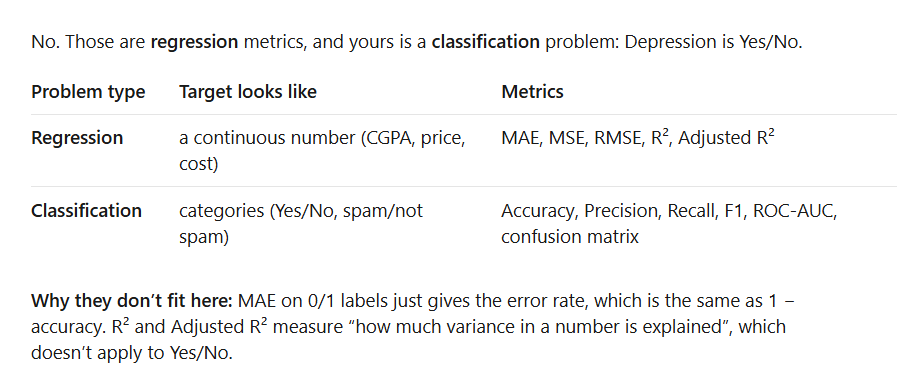

### 5) Model building with cross validation 

In [238]:


model_rf = RandomForestClassifier(random_state=42)
skf = StratifiedKFold(n_splits=10, shuffle=True, random_state=42)

scores = cross_validate(model_rf, x_train_ct, y_train, cv=skf,
                        scoring=["accuracy", "f1", "recall", "precision"])

for m in ["accuracy", "f1", "recall", "precision"]:
    s = scores[f"test_{m}"]
    print(f"{m:10}: {s.mean():.3f}")

accuracy  : 0.989
f1        : 0.979
recall    : 0.961
precision : 0.998


In [239]:
model_rf_2 = RandomForestClassifier(random_state=42)
skf = StratifiedKFold(n_splits=10, shuffle=True, random_state=42)

scores = cross_validate(model_rf_2, x_train, y_train, cv=skf,
                        scoring=["accuracy", "f1", "recall", "precision"])

for m in ["accuracy", "f1", "recall", "precision"]:
    s = scores[f"test_{m}"]
    print(f"{m:10}: {s.mean():.3f}")

accuracy  : 0.989
f1        : 0.978
recall    : 0.961
precision : 0.996


### 6)  Evaluation of results based on regression | classification problem 

In [240]:
model =  RandomForestClassifier(random_state=42)
model.fit(x_train_ct,y_train)

print(classification_report(y_test,model.predict(x_test_ct)))

              precision    recall  f1-score   support

           0       0.98      1.00      0.99       653
           1       1.00      0.95      0.97       240

    accuracy                           0.99       893
   macro avg       0.99      0.97      0.98       893
weighted avg       0.99      0.99      0.99       893



Gender : 0.020115195626523114 
Age : 0.028717104103157157 
Family_background : 0.047173586774668486 
Relationship_status : 0.04649501228846661 
Marital_status : 0.008851334030111492 
Living_style : 0.016770394016035913 
Current_semester : 0.08487737960099802 
CGPA : 0.03284789071400872 
friend_circle : 0.00567223483169978 
Health_condition : 0.01621945555732166 
Cost_without_study : 0.6734720719744495 
Home_division : 0.018788340482559597 


<Axes: >

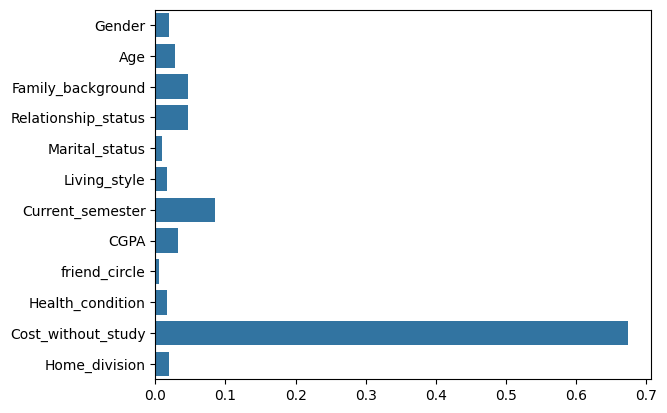

In [254]:
for i,j in zip(ct.feature_names_in_,model.feature_importances_):
    print(f"{i} : {j} ")
    

sns.barplot(x=model.feature_importances_,y=ct.feature_names_in_)

AUC SCORE :0.9986281265952016


Text(0, 0.5, 'True Positive Rate')

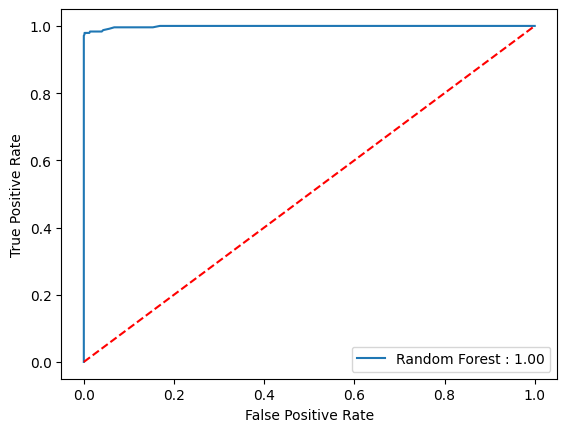

In [241]:
fpr,tpr,threshold =  roc_curve(y_test,model.predict_proba(x_test_ct)[:,1])
roc_auc = auc(fpr, tpr)


print(f"AUC SCORE :{roc_auc}")


plt.plot(fpr,tpr,label=f"Random Forest : {roc_auc :.2f}")
plt.plot([0,1],[0,1],"r--")
plt.legend()
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')